## ANALYSE EXPLORATOIRE DES DONNEES - EDA

In [4]:
# Mise a jour pour chaque execution
%load_ext autoreload
%autoreload 2

import sys
import os
import joblib
import json

# chemin du dossier
sys.path.append(os.path.abspath(".."))

# partons de la racine de notre projet
os.chdir("..")


import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# import de nos modules
from src.data_preprocessing import (clean_total_charges, build_preprocessor,  prepare_data_for_modeling)

from src.data_audit import load_raw_data

from src.data_vizualisation import (plot_target_distribution, graphiques_numeriques, 
plot_bivarie_numerical, plot_correlation, plot_interaction, plot_categorical_multivarie,
plot_churn_by_category, plot_feature_importance, plot_error_curve, plot_shap_summary,
plot_shap_waterfall, plot_gridsearch_results)

from src.data_analysis import (descriptive_churn, descriptive_variables_numeriques, analyse_numerique_by_target,
analyse_categorielle_by_target, correlation_spearman,interaction_num, evaluate_all_combinations,
get_feature_importance_from_combinations, calculate_vif, calculate_feature_importance, find_optimal_threshold,
get_errors_by_threshold)

from src.explication_shap import compute_shap_values

from src.modeling import (benchmark_models,get_logistic_coefficients, evaluate_final_model, 
save_final_artifacts, get_logistic_coefficients, tune_logistic_regression)

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import precision_recall_curve
from sklearn.metrics import confusion_matrix

from sklearn.model_selection import GridSearchCV


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [5]:
path= "V:\\1_PROJETS_DATA_SCIENCE\\09_Churn\\data\\Telco-Customer-Churn.csv"

df_raw = load_raw_data(path)
df_clear = clean_total_charges(df_raw)
display(df_clear.head(3))

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


## EDA 0- Analyse descriptive de la variable  cible : Churn

In [7]:
# Observation des modalités de notre variable cibe et verification de son equilibre
descriptive_churn(df_clear)

,Effectifs,Pourcentage
Churn,,
No,5174,73.463013
Yes,1869,26.536987


V:\1_PROJETS_DATA_SCIENCE\09_Churn\src\data_vizualisation.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Churn', palette='Set2')


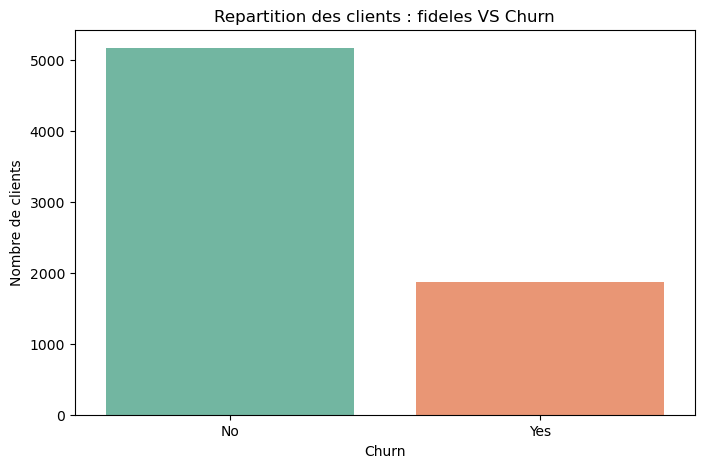

In [8]:
# visualisations du Churn
plot_target_distribution(df_clear)

# a- Observation
### interpretation statistique
- sur 7043 clients, environ 5000 clients sont restés soit 73,46 % contre 1869 clients qui sont partis soit 26,54 %

### conclusion metier:
le Churn touche plus d'un quart de la base client. Cela represente un enjeu financier majeur et une perte de revenus signficative

### implication pour la modelisation:
puisque qu'i existe un si grand ecart entre ces 02 classes, cela traduit un desequilibre et on doit en tenir compte dans la modelisation car, s'il est laissé ainsi, notre modele final aura tendance a predire 'Non' ce qui serait trompeur pour la metrique Accuracy(Exactitude)

il faut aussi remarquer que cette analyse est statique et nous nous indique pas si le Churn s'aggrave avec le temps ou est juste saisonier.

## EDA 2- Analyse Univariée - Variables Numeriques :
 variables numeriques
 - Tenure : ancienneté
 - MonthlyCharges : Charges mensuelles
 - TotalCharges : Total des charges

In [9]:
# statistiques descriptives des variables numeriques
descriptive_variables_numeriques(df_clear)

,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.35,89.85,118.75
TotalCharges,7043.0,2279.734304,2266.794470,0.00,398.55,1394.55,3786.60,8684.80


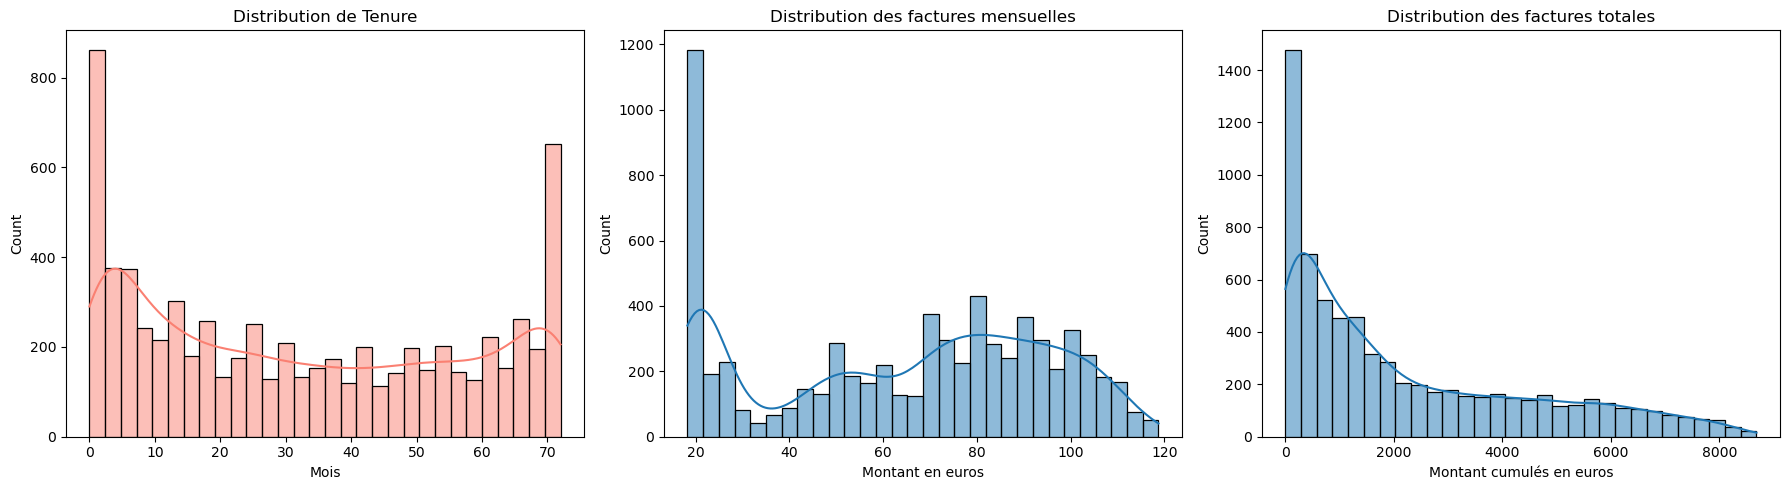

In [10]:
# graphiques des variables numeriques
graphiques_numeriques(df_clear)

# b- Observation et Interpretation :
- a. la variable : tenure
    * statistique : sa moyenne est de 32.37 mois, sa mediane est de 29 mois. l'ancienneté s'etend de 0 a 70 mois
    * Distribution : est en forme de U soit deux grandes valeurs 0 mois: pour nouveaux clients et 70 mois pour ancien client
    * Implication metier : L'entreprise presente un porte feuille polarisé : elle a de nouveaux clients(une concentration tres importante ayant 0 mois), les clients anciens qui presentent une concentration importante d'ancienneté (72 mois) et une autre categorie de clients presentant relativement une ancienneté plus ou moins importante.
    * Implication  technique : cette variable est cruciale . elle ne presente pas d'outliers. une standardisation pourrait etre necessaire.


- b. la variable MonthlyCharges
    * statistique : sa moyenne est de 64.76 et tres inferieur a sa mediane qui est de 70.35.:  Donc, une forte asymetrie 
    * Distribution : elle presente une distribution heterogene caracterisée par une forte concentration de clients a faible montants et plusieurs concentrations secondaires intermediaires et élevé. on ne peut pas conclure une distribution normale 
    * Implication metier : un fort pic de 20 euros pour des factures mensuelles et relativement d'autres pics de factures plus ou moins importantes. ces pics pourraient doivent etre creuser  avec d'autres variables pour en savoir plus
    * Implication  technique : cette variable est importante pour l'analyse.

    
- c. la variable TotalCharges

    * statistique : la moyene est 2279.73 et l'ecart type est 2266.79 montrent une grande variabilité dans le cumul des factures. 
    * Distribution : elle normale est tres asymetrique 
    * Implication metier : forte heterogeneité des montants cumulés facturés aux clients
    * Implication  technique : cette variable pourrait etre standardisé selon le modele. possiblement une transformation pour reduire l'asymetrie


## EDA 3- Analyse Bivarié :  CHURN ET Variables Numeriques 

- existe t' il une difference entre les clients qui resilient(yes) et ceux qui ne resilient pas (no) ?
- quelle caracteristiques distinguent statistiquement les clients qui partent de ceux qui restent ?
- si cette difference existe, alors quelle est l'intensité de cette difference ?
- cette difference peut elle presenter un interet pour la prediction churn ?

###  Bivarié: Churn et variable tenure

In [11]:
# boxplot des variables
variables_numeriques = ['tenure', 'MonthlyCharges', 'TotalCharges']
resultat = analyse_numerique_by_target(df_clear, variables_numeriques)
display(resultat)

,variable,Moyenne_Churn_yes,Moyenne_Churn_no,Mediane_Churn_yes,Mediane_Churn_no,Q1_Churn_yes,Q3_Churn_no,U_stat,p_value,Probability_superiorite,correlation_bisserale_rang,p_value_adj_holm
0,tenure,17.9791,37.5700,10.00,38.000,29.0,61.00,2515538.0,2.419636e-208,0.260133,-0.479734,7.258907e-208
1,TotalCharges,1531.7961,2549.9114,703.55,1679.525,2331.3,4262.85,3381224.0,5.685034e-83,0.349654,-0.300692,1.137007e-82
2,MonthlyCharges,74.4413,61.2651,79.65,64.425,94.2,88.40,6003125.5,3.311628e-54,0.620786,0.241571,3.311628e-54


# c- observations pour la variable tenure

### conclusion statistique
- la p-value ajustée(Holm) est extrement faible (proche de zero) : nous rejetons l'Hypothèse H0: les distributions sont signficativement differentes.
- la probabilité de Supériorité est de 0.26 signifiant ainsi qu'il y'a 74% de chances qu'un  client tiré au hasard dans le group_No(clients qui restent) ait une ancienneté supérieur a un client du group_Yes(ceux qui partent).
- la correlation bisserale de rang : indique une association negative d'une intensité modéré a forte.

  
### conclusion Metier 
- la faible ancienneté est le marqueur le plus discriminant du Churn. les clients qui partent sont majoritairement des nouveaux clients(mediane de 10 mois par rapport a mediane de 38 mois pour les clients fidèles).
- Le Risque de resiliation du contrat est donc sur la periode d'onboarding

### Implication metier 
c'est une variable qui a un fort pouvoir de prediction. sa distribution etant en U (bimodale), les modèles d'Arbres capteront bien les effets de seuil.

# d- observations pour la variable TotalCharges

### conclusion statistique
- la p-value ajustée(Holm) est extrement faible (proche de zero) : nous rejetons l'Hypothèse H0: les distributions sont signficativement differentes.
- la probabilité de Supériorité est de 0.35 signifiant ainsi que les Churners ont tendance a avoir des montants cumulés plus faible que les clients fidèles. 
- la correlation bisserale de rang : indique une association negative d'une intensité faible.

### conclusion Metier 
- Bien que significatif, le resultat pourrait etre liée a la variable tenure (anncienneté) car un client qui part au bout de moins de mois n'a pas le temps de generer une facture élévée. cette variable mesure la valeur historique du client. Les churners sont souvent des clients a faible historique car n'ayant pas duré dans la relation.

### Implication metier 
c'est une variable qui renverrait possiblement une information que donne deja l'ancienneté. ainsi, il pourrait y avoir un fort risque de multicolinearité avec la variable tenure(ancienneté). Dans un modèle lineaire, cela peut fausser les coefficients d'ou la prudence.

# e- observations pour la variable MonthlyCharges

### conclusion statistique
- la p-value ajustée(Holm) est extrement faible (proche de zero) : nous rejetons l'Hypothèse H0: les distributions sont signficativement differentes.
- la probabilité de Supériorité est de 0.62 signifiant ainsi que les Churners ont une probabilité plus élévée d'avoir des factures mensuelles superieure a celles des non-Churnés.
- la correlation bisserale de rang : indique une association positive d'une intensité faible.

### conclusion Metier 
- A l'inverse de l'ancienneté, le montant payé chaque mois un facteur de risque pour les departs(pas de renouvellement de contrat). les clients qui partent ont tendance a payer plus cher(mediane a 79.65 euros contre 64.42 euros) que ceux qui restent.
- Cela peut suggerer une sensibilité au prix des offres, ou peu etre un sentiment de mauvaise adequation entre le service et cout ou peu etre voir une concurrence plus aggressives pour les offres premiums.

### Implication metier 
c'est une variable indispensable au modele, avec un effet positif sur le risque. sa distribution multi-modale sera bien capté par les modèles d'Arbres. il est necessaire de la standardiser afin de la mettre en echelle avec les autres variables.

.

## EDA 3- Analyse Bivarié :  CHURN ET Variables categorielles 

- existe t' il une difference une association entre le Churn et les autres variables qualitatives ?
- si cette difference existe, alors quelle est l'intensité de cette difference ?
- quelle modalité presentent des taux de Churn particulierement élévé ou faibles?

# a.1.- Reponses a ces deux premieres questions
- existe t' il une difference une association entre le Churn et les autres variables qualitatives ?
- si cette difference existe, alors quelle est l'intensité de cette difference ?

In [12]:
variables_categorielles = ['gender', 'SeniorCitizen', 'Partner', 'Dependents',
                           'PhoneService', 'MultipleLines', 'InternetService',
                           'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
                           'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
                           'PaymentMethod']
resultat_cat = analyse_categorielle_by_target(df_clear, variables_categorielles)
display(resultat_cat)

,Variable,Chi_2_stat,p_value,Cramers_V,Decision,p_value_adj_holm
0,Contract,1184.5966,5.863038e-258,0.410,Existence de lien,9.380861e-257
1,OnlineSecurity,849.9990,2.661150e-185,0.347,Existence de lien,3.991724e-184
2,TechSupport,828.1971,1.443084e-180,0.343,Existence de lien,2.020318e-179
3,InternetService,732.3096,9.571788e-160,0.322,Existence de lien,1.244332e-158
4,PaymentMethod,648.1423,3.682355e-140,0.303,Existence de lien,4.418826e-139
5,OnlineBackup,601.8128,2.079759e-131,0.292,Existence de lien,2.287735e-130
6,DeviceProtection,558.4194,5.505219e-122,0.282,Existence de lien,5.505219e-121
7,StreamingMovies,375.6615,2.667757e-82,0.231,Existence de lien,2.400981e-81
8,StreamingTV,374.2039,5.528994e-82,0.231,Existence de lien,4.423196e-81
9,PaperlessBilling,258.2776,4.073355e-58,0.191,Existence de lien,2.851348e-57


# f- Observations
- 1ere observation: toutes variables ont un lien avec la variables cible.

les variables ont ete categorisées en  03 facteurs uniquement pour l'interpretation: facteurs structurants pour Valeur de Cramer > 0.3 , facteurs d'engagement pour les valeurs de Cramer compris entre [0.2 et 0.3] et les facteurs secondaires pour les valeurs de Cramer compris entre [0.1 et 0.2]
##  les facteurs structurants(Cramer_V > 0.3):
- Conclusion statistique :
    - le "Contrat" est la variable la plus forte en terme d'association avec le Churn(Cramer_V = 0.410).
    - "OnlineSecurity" et "TechSupport" ont des valeurs de Cramer_V respectifs de 0.347 et 0.343. ces variables sont significatives donc ont une association tout aussi forte avec le Churn.
    - "InternetService" a un lien significatif avec le Churn et son intensité est modéré a fort.

- Interpretation metier :
    - le type d'engagement est le premier facteur de risque. si les contrats sont des engagements mois par mois, elle pourrait etre a l'origine des departs massifs .
    - les clients qui n'ont pas souscrit pour ces services, partent beaucou plus. l'absence de support et de securité est un marqueur de desengagement de contrat.
    - le service Internet est associé a un Churn élévé.Très souvent ce type de technologie est très competitif a cause du type de technologie, pour ce cas Fibre optique et DSL.

- Interpretation pour la modelisation:
    - le contrat est une variable tres importante pour le modèle.
    - ces autres variables "OnlineSecurity" et "TechSupport" sont des signaux forts a conserver dans le modèle et permettra d;identifier les clients fragiles sur le plan des services
    - le service Internet est une variable a conserver car elle nous permettra de capter la difference de risque entre la fibre optique et le DSL(qui sont les modalités de la variable InternetService).

## les facteurs  d'engagement(0.2< Cramer_V <  0.3) :
- Conclusion statistique :
    - La variable PaymentMethod a un Cramer_V de 0.303 qui est significatif au Churn avec une intensité de relation moyenne.
    - les variables "OnlineBackup", "DeviceProtection", "ServiceStreamingTV", "StreamingMovies" peuvent etre vu comme des services additionnels. les resultats du test montrent qu'ils sont aussi associatifs a la variable Churn mais avec un effet faible sur la variable cible Churn.


- Interpretation metier :
    - le mode de paiement peut etre un facteur qui permet l'engagement des clients ou le Churn. ainsi, Un mode de paiement complexe est un facteur de desengagement. le type de contrat et les modes de paiement pourrait plus nous renseignés sur la difference entre les clients moins engagés(Churn) et les clients engagés(No-Churn).
    - les Services additionnels("OnlineBackup", "DeviceProtection", "ServiceStreamingTV", "StreamingMovies" ) pour les clients peuvent rendre percus comme des offres qui completent les offres principales, d'ou un sentiment d'offre client complète. on aura tendance a croire que plus un client a des offres, plus il est verouillé. A l'inverse le manque de service complementaire favoriserait le depart.

- Interpretation pour la modelisation:
    - ces variables apportent de la visibilité ou de la granularité dans leur apport sur la comprehension des Churns. Mais, ces variables pourraient etre redondante dans l'information qu'elles apportent. A verifier et a limiter si cette redondance existe.

### les facteurs secondaires : (0.1< Cramer_V <  0.2) : 
- Conclusion statistique :
    - les variables "PaperlessBilling", "Dependants", "SeniorCitizen" ont une association au Churn mais l'effet sur celle ci est faible. 
  
- Interpretation metier :
    - les personnes ayant des charges ont tendances a etre un peu plus stables.
- Interpretation pour la modelisation:
    - ces variables ont poids moins important dans les decision du modele 

## les facteurs succeptible d'etre ecarter : (Cramer_V <  0.01) : 
- Conclusion statistique :
    - les variables "gender", "PhoneService",  ont une association au Churn mais l'effet sur celle ci est est enormement faible. 
  
- Interpretation metier :
    - Ces variables ne se presentent pas comme des marqueurs de fidelisation ou de desengagement.
    
- Interpretation pour la modelisation:
    - ces variables doivent etre confirmer sur leur importance dans la feature selection afin psur la necessité de reduire le bruit dans le modèle.

# a.2. Reponse a cette question 
- quelle modalité presentent des taux de Churn particulierement élévé ou faibles?

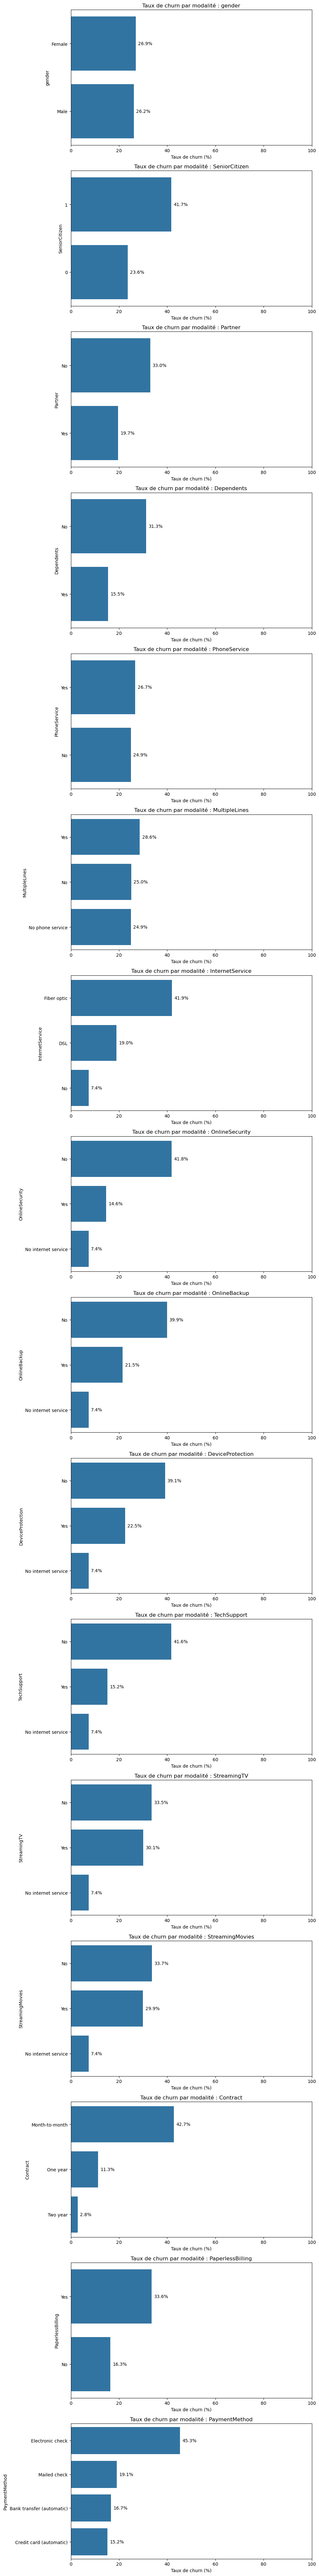

In [13]:
variables_categorielles = ['gender', 'SeniorCitizen', 'Partner', 'Dependents',
                           'PhoneService', 'MultipleLines', 'InternetService',
                           'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
                           'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
                           'PaymentMethod']
plot_churn_by_category(df_clear, variables_categorielles)

# g- Observations

### Conclusion statistique :
###### Variables Démographiques (Genre, Senior, Partenaire, Personnes à charge)
les variables suivantes : 
- gender : Aucune différence significative (26.9% vs 26.2%). Le V de Cramér était de 0.008, ce qui est négligeable.
- SeniorCitizen : Différence majeure. Les seniors ont un taux de churn de 41.7%, contre 23.6% pour les non-seniors.
- Partner et Dependents : Différences significatives. Les célibataires (33.0%) et les personnes sans personnes à charge (31.3%) partent beaucoup plus.
- PhoneService : presente une faible différence (26.7% vs 24.9%). le Cramer_V est 0.011 qui est l'intensité faible en relation avec le Churn.
- MultipleLines : montre une différence très faible (28.6% pour "Yes" contre 25.0% pour "No"). Le V de Cramér est très bas (0.04) en relation avec le Churn.
- Contract : Lien le plus fort du dataset (V de Cramér = 0.410). Le churn s'effondre de 42.7% (Month-to-month) à 11.3% (1 an) puis 2.8% (2 ans).
- PaymentMethod : Lien significatif (V = 0.303). Le chèque électronique est un signal d'alerte fort (45.3% de churn), contrairement aux prélèvements automatiques (~15-16%).
- PaperlessBilling : Lien modéré (V = 0.191). Ceux qui reçoivent la facture papier partent moins (16.3%) que ceux en dématérialisé (33.6%).
- InternetService : Lien fort (V = 0.322). La Fibre optique est un désastre (41.9% de churn) face au DSL (19.0%).
- OnlineSecurity & TechSupport : Liens très forts (V = 0.347 et 0.343). L'absence de ces services génère ~41% de churn, contre ~15% s'ils sont présents.
- OnlineBackup & DeviceProtection : Liens modérés (V = 0.292 et 0.282). Même dynamique : l'absence pousse vers la sortie (39%), la présence fidélise (~22%).
- La catégorie "No internet service" a toujours un taux très bas (~7.4%), car ces clients n'ont qu'une ligne téléphonique basique et sont très stables.
- StreamingTV & StreamingMovies : Liens faibles à modérés (V = 0.231 pour les deux). Les taux de churn sont très proches : ~30% si abonné, ~33.5% si non-abonné.

### Implication pour la modélisation :
pour la Feature Selection, les variables:
- gender pourrait etre supprimé (aucun apport prédictif, juste du bruit).
- SeniorCitizen, Partner et Dependents sont à conserver. Ils apporteront un contexte démographique utile au modèle pour segmenter les actions de rétention.
- Contract, PaymentMethod, PaperlessBilling : sont hautement prédictives et doivent être conservées. Contract sera la variable reine du modèle
- OnlineSecurity, OnlineBackup & DeviceProtection, Toutes ces variables sont à conserver.
- OnlineSecurity, OnlineBackup, DeviceProtection et TechSupport sont très corrélées entre elles (un client qui prend l'une prend souvent les autres). Les modèles d'arbres (Random Forest) géreront cela, mais pour une Régression Logistique, il faudra peut-être créer une variable synthétique "Nombre de services souscrits".
- StreamingTV & StreamingMovies: On peut les garder, mais elles auront un poids très faible dans le modèle. Si on cherche à simplifier le modèle à l'extrême, on pourrait les supprimer sans perdre beaucoup de performance.


.

## EDA - 4 : Etude multivariée : variables cible "Churn" et les autres variables categorielles

### EDA - 4.1 : Etude multivariée : variables cible "Churn" et les autres variables categorielles

L'objectif est de rechercher les combinaisons de modalités qui présentent les taux de churn les plus élevés, tout en vérifiant que ces résultats reposent sur des effectifs suffisants.L'objectif est de rechercher les combinaisons de modalités qui présentent les taux de churn les plus élevés, tout en vérifiant que ces résultats reposent sur des effectifs suffisants.

In [14]:
var_cat_globale = ['gender', 'SeniorCitizen', 'Partner', 'Dependents','PhoneService', 
                           'MultipleLines','InternetService', 'OnlineSecurity', 'OnlineBackup', 
                           'DeviceProtection', 'TechSupport','StreamingTV', 'StreamingMovies', 
                           'Contract', 'PaperlessBilling']

In [15]:
var_cat1 = ["Contract" , "OnlineSecurity", "TechSupport" , "InternetService"]
var_cat2 = ['PaymentMethod', "OnlineBackup", "DeviceProtection", "StreamingTV", "StreamingMovies"]
var_cat3= ["PaperlessBilling", "Dependents", "SeniorCitizen"]

In [16]:
# N'oublie pas df_clean (avec un n)
resultats = evaluate_all_combinations(df_clear, var_cat_globale)
display(resultats)

,Combinaison,Taille,Range_Churn (%),Max_Churn (%),Min_Churn (%),Pire_Profil,Meilleur_Profil,Nb_Clients_Max
0,SeniorCitizen + OnlineBackup + Contract,3,59.3,60.2,0.8,SeniorCitizen=1 & OnlineBackup=No & Contract=M...,SeniorCitizen=0 & OnlineBackup=No internet ser...,522
1,InternetService + OnlineBackup + Contract,3,57.6,58.4,0.8,InternetService=Fiber optic & OnlineBackup=No ...,InternetService=No & OnlineBackup=No internet ...,1436
2,SeniorCitizen + OnlineSecurity + Contract,3,57.3,58.2,0.8,SeniorCitizen=1 & OnlineSecurity=No & Contract...,SeniorCitizen=0 & OnlineSecurity=No internet s...,662
3,Partner + InternetService + Contract,3,57.3,57.8,0.5,Partner=No & InternetService=Fiber optic & Con...,Partner=Yes & InternetService=No & Contract=Tw...,1288
4,InternetService + OnlineSecurity + Contract,3,57.3,58.1,0.8,InternetService=Fiber optic & OnlineSecurity=N...,InternetService=No & OnlineSecurity=No interne...,1774
...,...,...,...,...,...,...,...,...
555,Partner + PhoneService,2,13.7,33.4,19.6,Partner=No & PhoneService=Yes,Partner=Yes & PhoneService=No,3270
556,gender + PhoneService + MultipleLines,3,5.6,29.2,23.6,gender=Male & PhoneService=Yes & MultipleLines...,gender=Male & PhoneService=Yes & MultipleLines=No,1485
557,gender + MultipleLines,2,5.6,29.2,23.6,gender=Male & MultipleLines=Yes,gender=Male & MultipleLines=No,1485
558,PhoneService + MultipleLines,2,3.7,28.6,24.9,PhoneService=Yes & MultipleLines=Yes,PhoneService=No & MultipleLines=No phone service,2971


In [17]:
# On regarde les 50 meilleures combinaisons pour être sûr
importance_vars = get_feature_importance_from_combinations(resultats, top_n=50)
display(importance_vars)

,Variable,Fréquence dans le Top 50
0,Contract,47
1,SeniorCitizen,16
2,InternetService,14
3,OnlineBackup,10
4,TechSupport,10
5,OnlineSecurity,9
6,Partner,8
7,MultipleLines,8
8,StreamingTV,7
9,StreamingMovies,7


# h- Observations

### Conclusion statistique :
- La domination absolue de Contract : Cette variable apparaît dans 47 des 50 meilleures combinaisons. 
Ensuite, viennent les variables SeniorCitizen (16), InternetService (14), OnlineBackup (10), TechSupport (10) et OnlineSecurity (9). Ce sont les variables qui, combinées au contrat, créent les écarts de churn les plus importants (Range > 50%).

- Les variables secondaires telles que Partner (8), MultipleLines (8), StreamingTV/Movies (7) et PaperlessBilling (5) apportent un affinage, mais ne sont pas les moteurs principaux des combinaisons extrêmes.

- Les variables écartées par l'algorithme sont notamment gender (2), PhoneService (2) et Dependents (2) sont quasiment absentes des meilleures combinaisons. 

### Conclusion métier :
- Le churn est un problème d'écosystème, pas de démographie : La machine a "compris" que pour trouver les clients qui partent, il faut regarder ce qu'ils achètent (Contrat, Internet, Services) et qui ils sont en termes de vulnérabilité (Senior), plutôt que leur genre ou s'ils ont une ligne téléphonique.

- Le profil "Senior vulnérable" : Le fait que SeniorCitizen soit la 2ème variable la plus fréquente prouve que la combinaison "Senior + Contrat mensuel + Options manquantes" est un segment critique.

- L'effet "Forfait complet" : La présence de OnlineBackup, OnlineSecurity et TechSupport dans le top montre que lorsqu'un client prend un forfait complet, il reste. Le churn touche ceux qui ont des forfaits incomplets.

### Implication pour la modélisation :
Pour la Feature selection, cette base statistique est notre socle en Feature Selection pour trier nos variables.

#### Variables à conserver  :
- les variables telles que : Partner, StreamingTV, StreamingMovies, PaperlessBilling sont a conserver.
- Par contre la variable de MultipleLines apparaît 8 fois ici, ce qui est surprenant vu son Cramer_V qui est faible (0.04). etant combinée à d'autres variables, elle peut avoir un micro-effet. On peut la garder pour un modèle complexe comme Random Forest, mais l'écarter d'un modèle simple.

### Variables à supprimer définitivement (Bruit) :
les variables succeptibles a etre ecarter definitivement sont :
- gender (Apparaît 2 fois, aucun V de Cramér)
- PhoneService (Apparaît 2 fois, aucun V de Cramér)

.

### EDA - 4.2. : Etude multivariée : variables cible "Churn" et les autres variables numeriques

In [18]:
variables_numeriques = ['tenure', 'MonthlyCharges', 'TotalCharges']
correlation = correlation_spearman(df_clear, variables_numeriques)
display(correlation)

,tenure,MonthlyCharges,TotalCharges,Churn_binaire
tenure,1.000000,0.276417,0.889696,-0.367062
MonthlyCharges,0.276417,1.000000,0.638028,0.184743
TotalCharges,0.889696,0.638028,1.000000,-0.229955
Churn_binaire,-0.367062,0.184743,-0.229955,1.000000


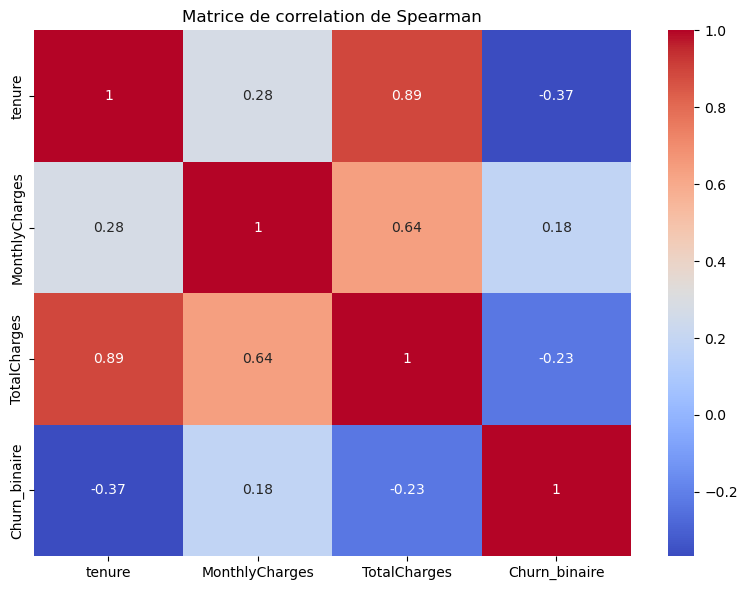

In [19]:
plot_correlation(correlation)

# Observation des 03 variables: tenure, MonthlyCharges, TotalCharges

#### conclusion statistique

- la variable tenure et la variable TotalCharges(correlation = 0.89): correlation forte.
- la variable MontlyCharges et TotalCharges(correlation = 0.64): modéré a moyenne 
- la variable tenure et MontlyCharges(correlation = 0.28): correlation faible, pas de lien entre ces deux variables.

# interpretation metier :
- la variable tenure est fortement correlée avec la variable TotalCharges(correlation = 0.89): cela pourrait montrer qu'un client ancien a forcement un total de factures élévé.
- il existe aussi un lien entre MontlyCharges et TotalCharges estimé a 0.64 . ce lien est de nature modéré a forte. es ce les clients avec des grosses factures sur la durée sont ceux ayant des services sur la FiBRE et les options ?
- tenure(l'ancienneté) n'est pas liée au prix car la correlation de spearman est de 0.28. en d'autre terme, un client ancien ne paie pas necessairement plus cher car un nouveau client peut arriver avec des factures élévées.plot_correlation(correlation)


# interpretation pour le modèle : 
- la multicolinearité existe entre la variable tenure et la variable TotalCharges. Ces deux variables donnent des informations redondantes. nous garderons 'tenure'.
- nous garderons aussi la variable MonthlyCharges

# Variable Churn_binaire : 
elle est une variable technique temporaire qui permet de comprendre comment varie Churn quand la variable autres variables augmentent ou diminuent. Elle permet de traduire cette correlation en comportement client comprehensible 

#### conclusion statistique 
Avec Churn_binaire,
- la variable tenure est correlé a -0.367 ce qui est une correlation forte et negative
- la variable MonthlyCharges est correlé a  + 0.184 ce qui est une correlation forte et positive
- la variable TotalCharges est correlé a -0.229 ce qui est une correlation faible et negative

### interpretation metier: 
- cette correlation tenure et Churn_binaire indique que plus la tenure(l'ancienneté) du client augmente, plus on observe une tendance a avoir une valeur faible. Autrement dit, les nouveaux clients semblent exposés qu risque de depart que les clients qui ont une longue ancienneté.
- cette correlation MonthlyCharges et Churn_binaire suggère que lorsque les mensualités augmentent, on observe une tendance a avoir une valeur élévé de Churn_binaire. Autrement dit, les clients ayant des mensualités élévées presentent une tendance legerement plus importante a resilier. Donc le niveau de mensualité pourrait constituer un facteur associé a l'insatisfaction
-  cette correlation TotalCharges et Churn_binaire suggère les clients ayant accumulés davantages des depenses aupres de l'entreprise sont generalement associés moins a la resiliation

.

# EDA - 5 : Analyse entre variable numerique: interaction
# tenure et MonthlyCharges
es ce que les mensualités élévées sont associées au Churn de la meme maniere chez les nouveaux clients et chez les anciens clients ?

# tenure et TotalCharges
es ce que les TotalCharges élévées sont associées au Churn de la meme maniere chez les nouveaux clients et chez les anciens clients ?

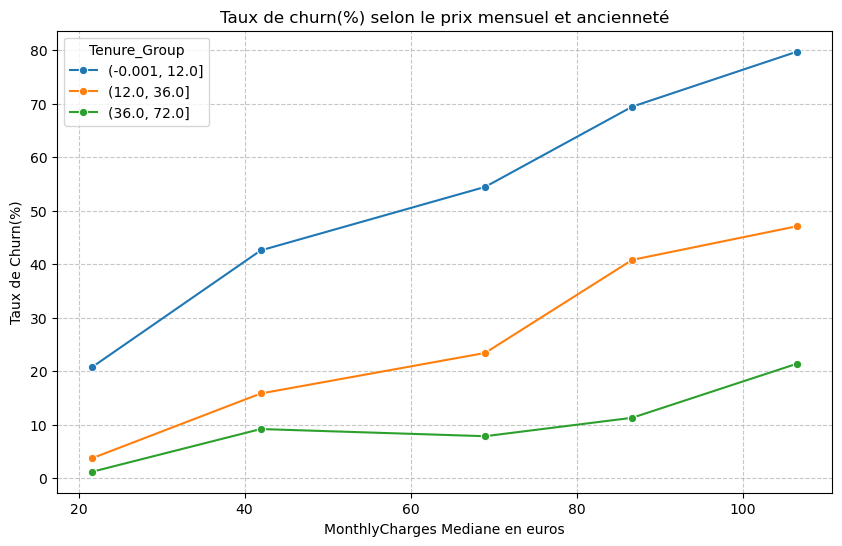

In [20]:
# graphique de comparaison de groupe en fonction de l'anciennete
plot_interaction(df_clear, 'MonthlyCharges')

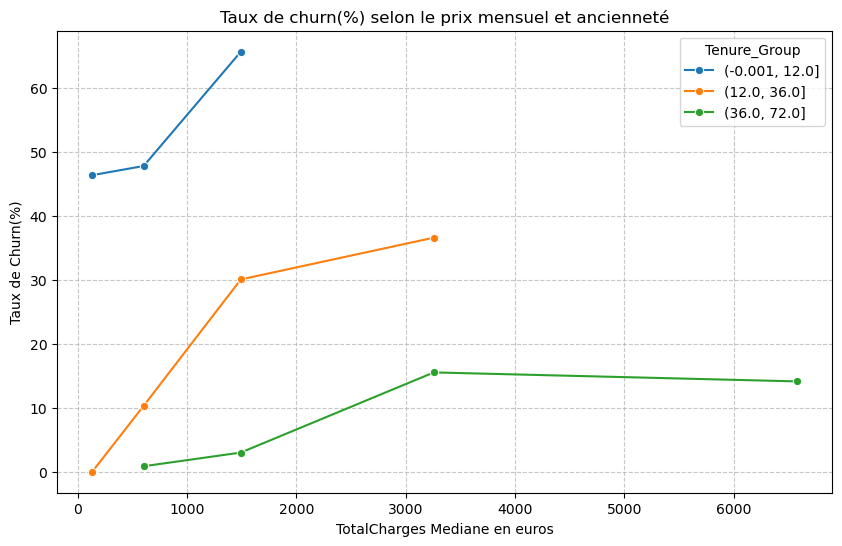

In [21]:
plot_interaction(df_clear, 'TotalCharges')

In [23]:
# affichage statistique
results_interaction = interaction_num(df_clear)
display(results_interaction)

,Segment_anciennete,Nombre_clients,Correlation_Prix_Churn
0,Nouveau(0-12) mois,2186,0.374
1,intermediaire(12-36)mois,1856,0.359
2,Anciens(37+)mois,3001,0.202


# Observation

### Conclusion statistique:
- les correlations de Spearman entre le prix mensuel et Churn sont toutes positives sont associés au risque. l'observation de correlation montre que leur intensité decroit avec la tenure(ancienneté). les graphiques ne font que confirmer cette tendance .
- les departs sont plus associés au factures mensuelles élévées. plus les mensualités sont élévés, plus le risque de depart des nouveaux clients est élévé
- pour les anciens clients meme s'ils paient des factures élévées, leur taux de churn reste contenu entre 10% a 20%
- le deuxieme graphique montre que ceux qui partent ont un faible Total de charges.

# Interpretation pour la modelisation:
on garde definitivement 'tenure' et 'MonthlyCharges' et on supprime TotalCharges

.

# FEATURE SELECTION - FS_1 - CHOIX DE VARIABLES POUR LA MODELISATION 

In [24]:
from src.data_vizualisation import plot_categorical_multivarie

In [25]:
from src.data_analysis import calculate_vif

In [26]:
# Liste des variables numériques candidates
variables_num = ['tenure', 'MonthlyCharges', 'TotalCharges']

# Appel de la fonction
df_vif = calculate_vif(df_clear, variables_num)

# Affichage du tableau
display(df_vif)

,Variable,VIF
0,tenure,5.84
1,MonthlyCharges,3.22
2,TotalCharges,9.51


# i- Obsrevations:

### Conclusion statistique :
- tenure (VIF = 5.84) : La valeur dépasse légèrement le seuil d'alerte de 5, indiquant une multicolinéarité modérée.
- MonthlyCharges (VIF = 3.22) : La valeur est inférieure à 5, indiquant une absence de multicolinéarité problématique. Cette variable est statistiquement "saine".
- TotalCharges (VIF = 9.51) : La valeur frôle le seuil critique de 10, signalant une multicolinéarité sévère. Cela confirme mathématiquement ce que la matrice de Spearman nous avait montré (corrélation de 0.89 avec tenure).

### Conclusion métier :
-  Il est tout à fait normal que TotalCharges ait un VIF aussi élevé. La facture totale n'est pas une décision indépendante du client, c'est le résultat mécanique de son ancienneté (tenure) multipliée par sa facture mensuelle (MonthlyCharges).
  
-  Le VIF acceptable de MonthlyCharges (3.22) prouve que le prix payé chaque mois est une information distincte de la durée de la relation client. Un client récent peut payer très cher, et un client ancien peut payer peu. Ces deux signaux sont complémentaires et non redondants.

### Implication pour la modélisation 
- La variable TotalCharges est officiellement écartée de notre pipeline de modélisation. La garder créerait de l'instabilité dans les modèles (surtout la Régression Logistique), car le modèle ne saurait plus à quelle variable attribuer le poids de la fidélité (l'ancienneté ou la facture totale).
- Décision de conservation : Nous conservons tenure et MonthlyCharges.
-  Bien que légèrement > 5, la variable tenure sera conserver car c'est notre variable numérique la plus prédictive. Les modèles basés sur les arbres (Random Forest) sont totalement insensibles à ce niveau de VIF. Si nous avions utilisé uniquement une Régression Logistique, nous aurions pu envisager de centrer/réduire les variables ou de créer une variable d'interaction.

,Variable,Importance
0,MonthlyCharges,0.275630
1,tenure,0.272526
2,Contract_Two year,0.068021
3,InternetService_Fiber optic,0.047962
4,PaymentMethod_Electronic check,0.042082
5,Contract_One year,0.034052
6,OnlineSecurity_Yes,0.031708
7,Partner_Yes,0.028220
8,PaperlessBilling_Yes,0.028077
9,TechSupport_Yes,0.027234


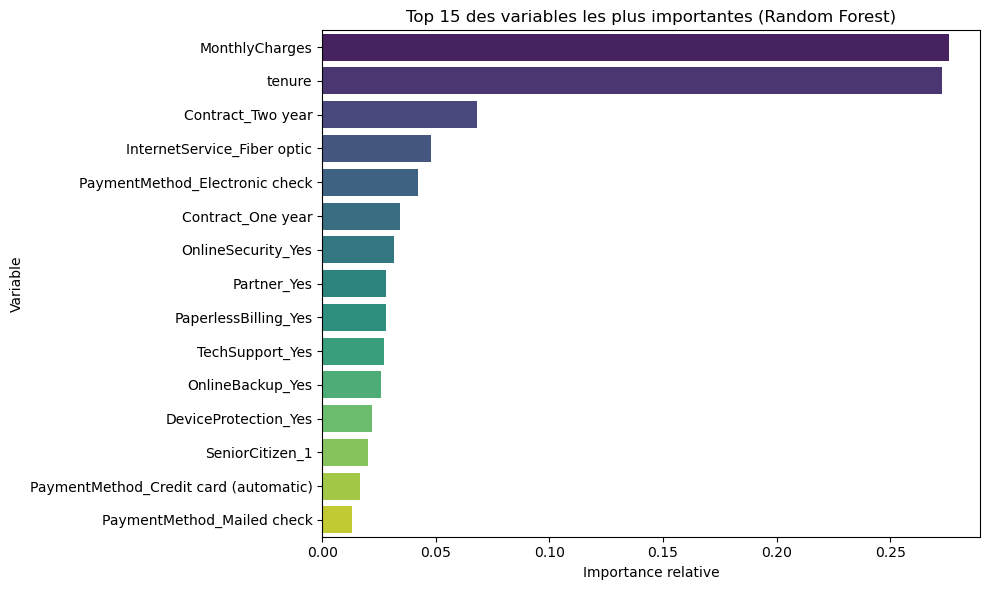

In [27]:
# 1. Préparation (Split)
X_train, X_test, y_train, y_test = prepare_data_for_modeling(df_clear)

# 2. Création du préprocesseur
preprocessor = build_preprocessor(
    num_features=['tenure', 'MonthlyCharges'], 
    cat_features=['Contract', 'InternetService', 'TechSupport', 'OnlineSecurity', 
                  'OnlineBackup', 'DeviceProtection', 'PaymentMethod', 
                  'SeniorCitizen', 'Partner', 'PaperlessBilling']
)

# 3. Calcul de l'importance (Analyse)
df_importance = calculate_feature_importance(X_train, y_train, preprocessor)

# 4. Affichage (Visualisation)
display(df_importance.head(15))
plot_feature_importance(df_importance, top_n=15)

# Conclusion statistique :
- Les variables numériques dominantes sont : MonthlyCharges (27.5%) et tenure (27.2%) écrasent le classement. À elles deux, elles portent plus de 54% de la décision du modèle.

- Le poids de la variable contrat dont les modalités Contract_Two year (6.8%) et Contract_One year (3.4%) sont très fortes.

- La 2eme conclusion montre les variables telles que: InternetService_Fiber optic (4.7%), PaymentMethod_Electronic check (4.2%), OnlineSecurity_Yes (3.1%) et TechSupport_Yes (2.7%) complètent le top 10.

- Nous observons aussi l'absence des modalités de référence telles que Contract_Month-to-month n'apparaît pas. C'est normal.

- Lors du One-Hot Encoding (drop='first'), cette modalité a été choisie comme référence (baseline). Le modèle mesure l'impact par rapport à elle. L'importance des contrats 1 an et 2 ans presente factuellement et indirectement le danger du contrat mensuel.

# Implication pour la modélisation :
- Pour la validation de la Feature Selection : Les variables gender, PhoneService et MultipleLines sont totalement absentes du top 15. La décision de les écarter était donc la bonne. Le modèle est plus "propre" et plus rapide sans elles.
- Important a rappeler: Pas de Data Leakage car le fait que ces variables (qui étaient dans le dataset) n'apparaissent pas prouve que le modèle a été entraîné de manière saine sur X_train et n'a pas triché.

In [28]:
# 1. Préparation
X_train, X_test, y_train, y_test = prepare_data_for_modeling(df_clear)

# 2. Préprocesseur
preprocessor = build_preprocessor(
    num_features=['tenure', 'MonthlyCharges'], 
    cat_features=['Contract', 'InternetService', 'TechSupport', 'OnlineSecurity', 
                  'OnlineBackup', 'DeviceProtection', 'PaymentMethod', 
                  'SeniorCitizen', 'Partner', 'PaperlessBilling']
)

# 3. Benchmark
df_benchmark = benchmark_models(X_train, y_train, X_test, y_test, preprocessor)
display(df_benchmark)

C:\Users\PC\anaconda3\envs\data_science\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)
C:\Users\PC\anaconda3\envs\data_science\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\PC\anaconda3\envs\data_science\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was f

,Modèle,TP,TN,FP,FN,Recall,Precision,F1-Score,ROC-AUC
0,SVM,288,771,264,86,0.770,0.522,0.622,0.811
1,Logistic Regression,300,737,298,74,0.802,0.502,0.617,0.837
2,SGD Classifier,283,774,261,91,0.757,0.520,0.617,0.836
3,LightGBM,277,779,256,97,0.741,0.520,0.611,0.834
4,CatBoost,273,785,250,101,0.730,0.522,0.609,0.836
5,Decision Tree,290,734,301,84,0.775,0.491,0.601,0.828
6,XGBoost,254,798,237,120,0.679,0.517,0.587,0.817
7,Random Forest,234,844,191,140,0.626,0.551,0.586,0.809
8,Naive Bayes,320,631,404,54,0.856,0.442,0.583,0.811
9,Gradient Boosting,191,932,103,183,0.511,0.650,0.572,0.843


# notre comprehension
FN (Faux Négatif) : On prédit qu'il reste, mais il part. C'est le pire scénario. (Perte du client).
FP (Faux Positif) : On prédit qu'il part, mais il reste. C'est moins grave. (Coût d'un appel ou d'une remise inutile).

# Les Resultats les plus extrêmes :

- Naive Bayes a le meilleur Recall (0.856) mais il génère 404 Faux Positifs. Le service client va devoir appeler 404 clients fidèles pour rien. C'est ingérable opérationnellement.

- AdaBoost (Precision 0.677) est très précis, mais il rate 196 churners (Recall 0.476). C'est une catastrophe financière.

#  SVM vs Régression Logistique
- Le SVM (Support Vector Machine) : C'est le grand gagnant du F1-Score (0.622). Il a un excellent Recall (0.770) et un bon ROC-AUC (0.811).
- La Régression Logistique : Elle est juste derrière (F1 0.617), mais elle a un meilleur Recall (0.802). Cela signifie qu'elle ne rate que 74 churners (contre 86 pour le SVM), tout en ayant un ROC-AUC supérieur (0.837).

# Le Choix du Modèle final : La Régression Logistique
- le SVM a un meilleur F1-Score que tous mais la Régression Logistique a un meilleur recall que SVM.
- En ce concentrant sur Le coût métier : la Régression Logistique a le 2ème meilleur F1-Score, mais surtout un excellent Recall (80%). Cela voudrait dire qu'elle détecte plus de clients en danger.
- Elle est robuste et est généralement moins exposée au surapprentissage que des modèles plus complexes comme les arbres profonds ou les réseaux de neurones.
- Elle ne cherche pas à apprendre des règles complexes automatiquement.

In [29]:
# ré-entraînement le modèle gagnant sur le Train (s'il n'est pas déjà dans une variable)
log_reg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)) ])
log_reg_pipeline.fit(X_train, y_train)

# Extraction des coefficients
df_coefs = get_logistic_coefficients(log_reg_pipeline, top_n=7)
display(df_coefs)

,Variable,Coefficient
0,InternetService_Fiber optic,0.477869
1,PaymentMethod_Electronic check,0.446591
2,PaperlessBilling_Yes,0.382967
3,MonthlyCharges,0.382602
4,SeniorCitizen_1,0.240466
5,PaymentMethod_Mailed check,0.064652
6,DeviceProtection_Yes,0.009799
7,Contract_Two year,-1.412002
8,Contract_One year,-0.724953
9,tenure,-0.666008


# Conclusion statistique :

- Les coefficients positifs (en haut) augmentent la probabilité de churn (log-odds). Les coefficients négatifs (en bas) la diminuent.
- Le poids de l'engagement : Contract_Two year (-1.412) et Contract_One year (-0.724) sont les coefficients négatifs les plus forts du modèle.
- Le poids du risque : InternetService_Fiber optic (+0.478), PaymentMethod_Electronic check (+0.447) et PaperlessBilling_Yes (+0.382) sont les principaux moteurs de départ.
- Le signal de l'ancienneté : tenure (-0.666) confirme que chaque mois passé chez l'opérateur réduit significativement le risque.
-  DeviceProtection_Yes a un coefficient positif très faible (0.009). Le modèle considère qu'avoir cette option seule ne protège pas, contrairement au Support et à la Sécurité.

# Conclusion métier :

- Le bouclier contractuel : L'effet de l'engagement (surtout 2 ans) écrase tout le reste. Un contrat de 2 ans "annule" presque l'effet néfaste de la Fibre optique ou du paiement électronique.

- Le paradoxe de la Fibre : La Fibre est le produit le plus cher, donc le plus sensible à la concurrence et à l'insatisfaction.

- L'effet "Lock-in" (verrouillage) : OnlineSecurity_Yes (-0.484) et TechSupport_Yes (-0.374) prouvent que les services d'accompagnement retiennent le client. Ils ont peur de perdre ces avantages s'ils partent.

# Implication pour le moteur de décision métier (Étape suivante) :

Ces coefficients nous donnent les "règles" exactes pour le conseiller.

- Règle 1 (Alerte maximale) : Si un client a un contrat Month-to-month (référence, donc coefficient 0, mais la baseline est déjà risquée), qu'il est en Fibre, et qu'il paie par chèque électronique, il cumule les pires facteurs. Le conseiller doit intervenir immédiatement.

- Règle 2 (Action de rétention) : Si le client est proche de la sortie, le meilleur levier pourrait etre de lui proposer un passage à un contrat 1 an ou 2 ans (le coefficient négatif est énorme).

In [32]:
# Récupérer les probabilités du modèle sur le Test
y_proba = log_reg_pipeline.predict_proba(X_test)[:, 1]

# Calculer la précision et le rappel pour plusieurs seuils
precisions, recalls, thresholds = precision_recall_curve(y_test, y_proba)

# Trouver le seuil qui maximise le F1-Score
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_threshold = thresholds[np.argmax(f1_scores)]

print(f"Le seuil optimal pour maximiser le F1-Score est : {best_threshold:.3f}")

NameError: name 'np' is not defined

In [33]:
# Recuperation des probabilités du modèle (Régression Logistique)
y_proba = log_reg_pipeline.predict_proba(X_test)[:, 1]

resultat_seuil = find_optimal_threshold(y_test, y_proba)

# Affichage de resultat
print(f"Le seuil optimal (qui maximise le F1) est de : {resultat_seuil['optimal_threshold']}")
print(f"Le F1-Score maximum atteint est de : {resultat_seuil['max_f1_score']}")

# Application du nouveau seuil :
y_pred_optimal = (y_proba >= resultat_seuil['optimal_threshold']).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred_optimal).ravel()
print(f"\nAvec ce seuil ({resultat_seuil['optimal_threshold']}) :")
print(f"Faux Négatifs (FN) : {fn} (Clients perdus non détectés)")
print(f"Faux Positifs (FP) : {fp} (Clients contactés inutilement)")

Le seuil optimal (qui maximise le F1) est de : 0.562
Le F1-Score maximum atteint est de : 0.621

Avec ce seuil (0.562) :
Faux Négatifs (FN) : 95 (Clients perdus non détectés)
Faux Positifs (FP) : 245 (Clients contactés inutilement)


# Conclusion statistique :
- Le seuil qui maximise mathématiquement le F1-Score est de 0.562 (supérieur au seuil par défaut de 0.5). Le F1-Score atteint 0.621.
- En passant de 0.5 à 0.562, le modèle devient plus "strict" : il exige une probabilité plus forte pour classer un client comme churner.

- Conséquence sur la matrice de confusion : Les Faux Positifs (FP) diminuent (de 297 à 245), mais les Faux Négatifs (FN) augmentent (de 74 à 95). Le modèle est devenu plus précis, mais moins sensible.

# Conclusion métier :

Le F1-Score est aveugle au coût métier. Il traite une erreur de type I (FP) et de type II (FN) de manière strictement égale.
Or, pour l'entreprise, ce n'est pas vrai, rater 21 clients supplémentaires (les 95 FN au lieu de 74) représente une perte de revenus massive. À l'inverse, contacter 52 clients fidèles en trop (les 245 FP au lieu de 297) ne coûte qu'un temps au conseiller.

# Décision métier 
Nous allons refuser le seuil de 0.562. L'entreprise préfère "sacrifier" la précision mathématique pour maximiser la rétention.

# Implication pour la modélisation (Le seuil métier) :
Nous allons forcer un seuil plus bas (par exemple 0.35 ou 0.40) dans notre application finale.
En baissant le seuil, nous allons accepter plus de Faux Positifs (le conseiller appellera des gens qui allaient rester), mais nous allons faire chuter drastiquement les Faux Négatifs (nous sauverons plus de clients).

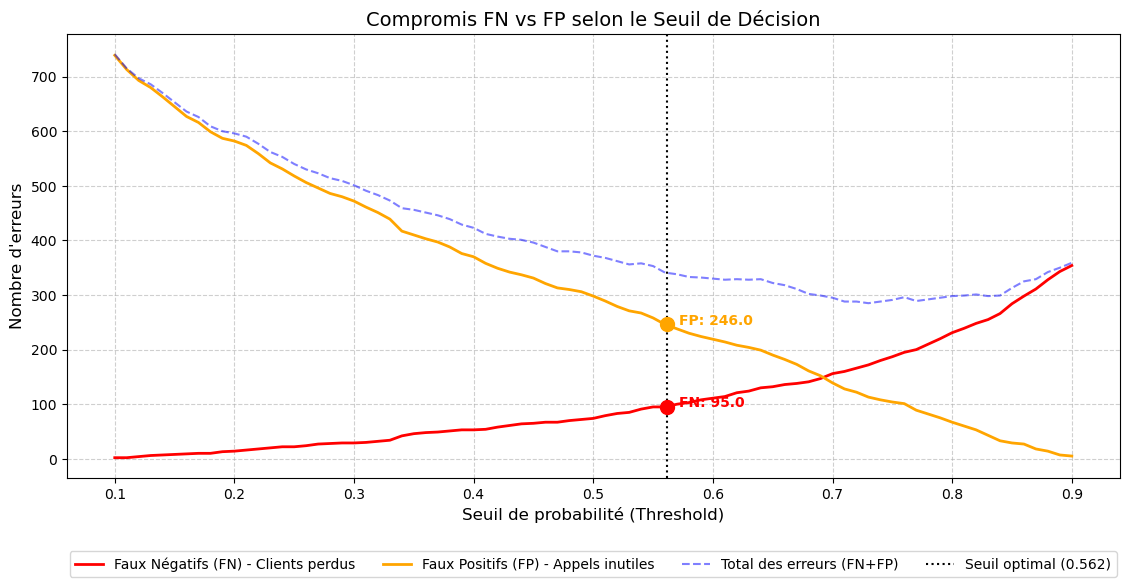

In [34]:
# Calcul des erreurs (on utilise y_test et y_proba)
df_errors = get_errors_by_threshold(y_test, y_proba)

# Tracé de la courbe avec le seuil de 0.562
plot_error_curve(df_errors, chosen_threshold=0.562)

# Conclusion statistique :
- La courbe bleue en pointillés (Total des erreurs) forme un "U". Son point le plus bas correspond exactement au seuil de 0.562. C'est l'optimum mathématique qui maximise le F1-Score. À ce point précis, on a 95 FN (clients perdus) et 246 FP (fausses alertes).

- La ligne rouge (FN) et la ligne orange (FP) évoluent en sens inverse : c'est le principe fondamental du compromis biais-variance. On ne peut pas minimiser les deux en même temps.

# Conclusion métier:
- L'asymétrie des coûts : Si on reste à 0.562, on perd 95 clients. Si on baisse le seuil à 0.40, on va certes augmenter les FP (disons à 400 appels inutiles), mais on va faire chuter les FN (disons à 50 clients perdus).

- Le calcul est simple : Est-ce que l'entreprise préfère faire 150 appels téléphoniques de plus (ce qui coûte quelques heures de travail) pour sauver 45 clients (ce qui représente des milliers d'euros de revenus) ? La réponse est oui, sans hésiter.

- Le seuil de 0.562 est donc le "meilleur seuil mathématique", mais le seuil de 0.40 sera notre "seuil métier" pour maximiser la rétention.

# Implication pour la modélisation notamment le deployement:
- Dans l'application Streamlit, nous n'allons pas utiliser le seuil de 0.5 par défaut. Mais, nous allons baisser a  un seuil plus bas soit un exemple de 0.40 pour baisser 

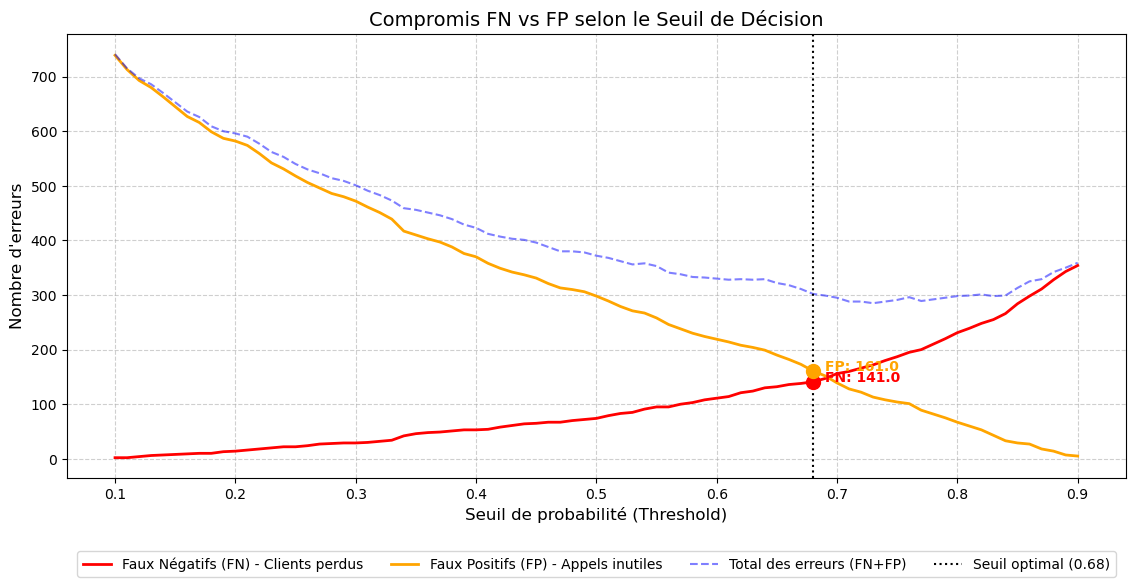

In [35]:
# Calcul des erreurs (on utilise y_test et y_proba)
df_errors = get_errors_by_threshold(y_test, y_proba)

# Tracé de la courbe avec le seuil de 0.562
plot_error_curve(df_errors, chosen_threshold=0.68)

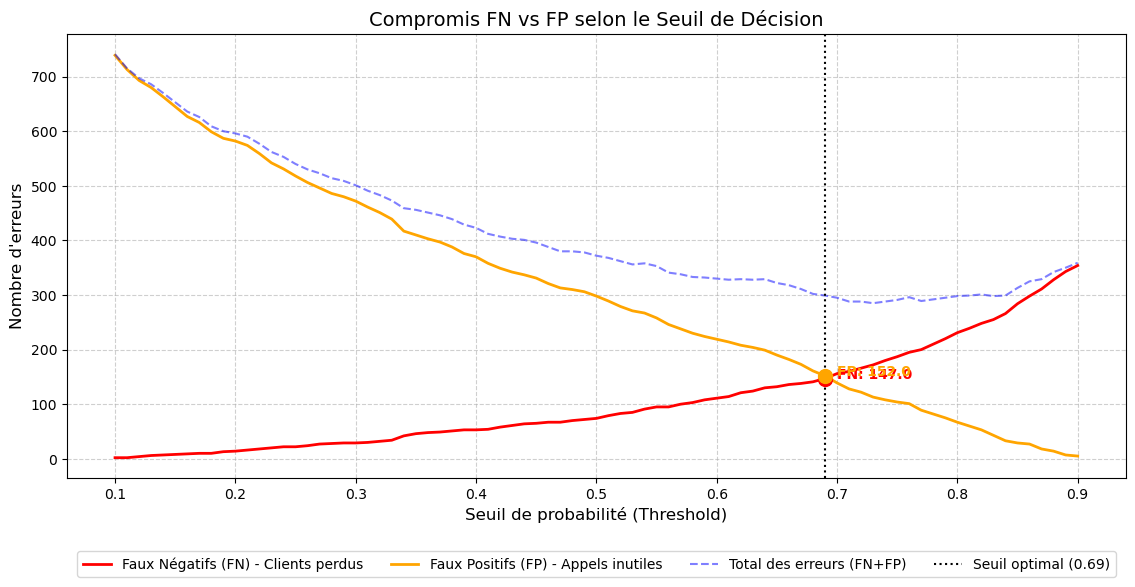

In [36]:
# Calcul des erreurs (on utilise y_test et y_proba)
df_errors = get_errors_by_threshold(y_test, y_proba)

# Tracé de la courbe avec le seuil de 0.562
plot_error_curve(df_errors, chosen_threshold=0.69)

le meilleur compromis est au seuil de 0.69 qui produit FN =147 et FP = 152. cela traduit de l'equilibre entre les clients perdus et les appels inutiles passés qu client aui sont succeptible de ne pas etre churner. Mais la problematique est de reduire les clients perdus d'ou il serait interessant de reduire le seuil optimal autour de 0.40.

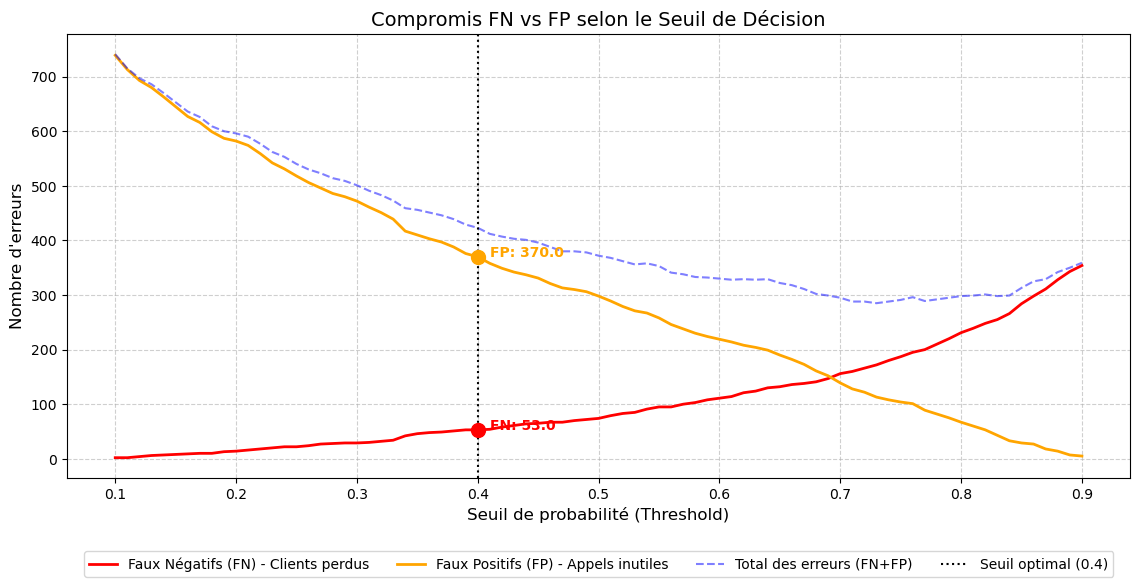

In [37]:
# Calcul des erreurs (on utilise y_test et y_proba)
df_errors = get_errors_by_threshold(y_test, y_proba)

# Tracé de la courbe avec le seuil de 0.562
plot_error_curve(df_errors, chosen_threshold=0.40)

"Le choix du seuil de décision repose sur un arbitrage entre le coût de la perte d'un client et la capacité opérationnelle des équipes de rétention. Bien que le seuil de 0.562 minimise le nombre total d'erreurs, il génère 95 Faux Négatifs. En abaissant le seuil à 0.40, nous réduisons les Faux Négatifs à 55 (sauvant 40 clients supplémentaires), au prix environ de 124 Faux Positifs additionnels. Ce compromis a été jugé optimal. Descendre en dessous de 0.30 saturerait le service client avec plus de 500 appels, sans gain significatif sur la rétention."

.

# EXPLICATION DU SHAP

Objectif : Comprendre quelles variables influencent le plus le modèle (niveau global) et expliquer pourquoi un client spécifique a reçu un score de risque élevé (niveau individuel).

In [38]:
# Préparation des données
X_train, X_test, y_train, y_test = prepare_data_for_modeling(df_clear)

# Préprocesseur
preprocessor = build_preprocessor(
    num_features=['tenure', 'MonthlyCharges'], 
    cat_features=['Contract', 'InternetService', 'TechSupport', 'OnlineSecurity', 
                  'OnlineBackup', 'DeviceProtection', 'PaymentMethod', 
                  'SeniorCitizen', 'Partner', 'PaperlessBilling']
)

# Entraînement
final_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])
final_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['tenure','MonthlyCharges','Contract',...,'SeniorCitizen','Partner', 'PaperlessBilling']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pas

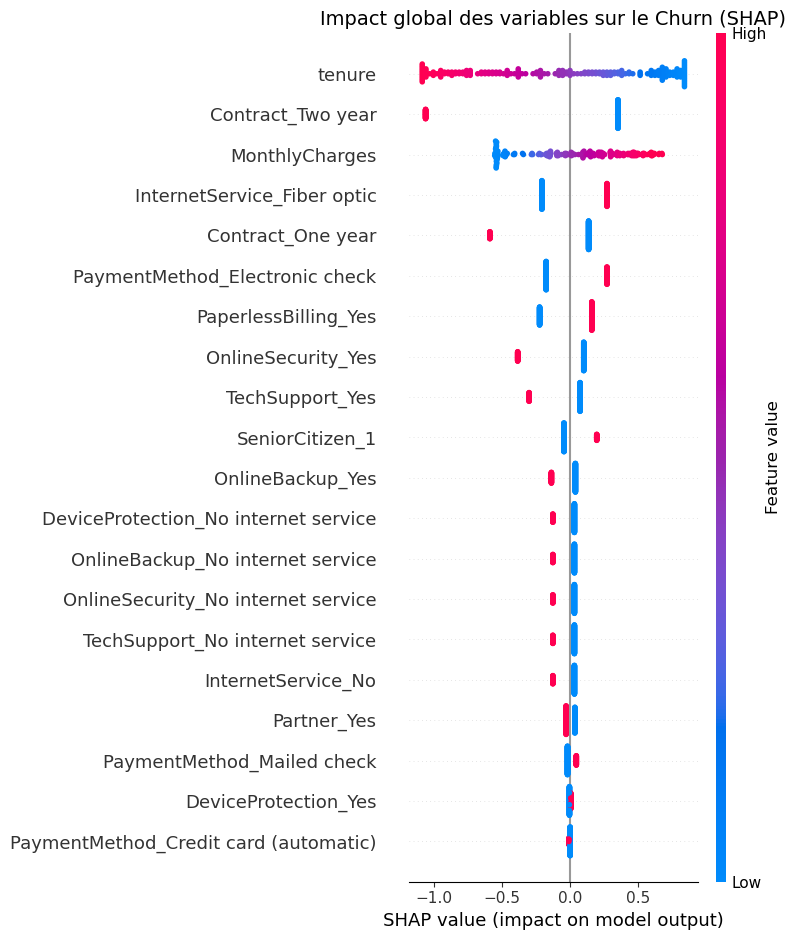

In [44]:
# Échantillon de 200 clients
X_test_sample = X_test.sample(200, random_state=42)

# Calcul (on récupère 2 objets : les valeurs SHAP ET les données transformées)
shap_values_global, X_transformed_global = compute_shap_values(final_pipeline, X_test_sample)

# Affichage
plot_shap_summary(shap_values_global, X_transformed_global)

# Interprétation Globale
Ce graphique explique comment le modèle prend ses décisions sur l'ensemble de la population (200 clients comme l'échantillon).

L'axe horizontal (valeur SHAP) montre si la variable pousse le client vers le Churn (à droite, valeurs positives) ou vers la fidélité (à gauche, valeurs négatives). La couleur indique la valeur de la variable (Rouge = valeur élevée, Bleu = valeur faible).

- tenure (Ancienneté) est la variable reine. Elle est la plus étalée sur l'axe. Les points bleus (faible ancienneté) sont à droite : une faible ancienneté pousse fortement vers le churn. Les points rouges (forte ancienneté) sont à gauche : une ancienneté élevée protège le client.
- Contract_Two year est un bouclier : Les points rouges (ceux qui ont un contrat 2 ans) sont massivement regroupés à l'extrême gauche. Avoir ce contrat réduit drastiquement le risque. À l'inverse, ne pas l'avoir (points bleus) pousse vers le churn.
- Les facteurs de risque (poussent à droite) :
  - MonthlyCharges : Les points rouges (factures élevées) sont à droite. Payer cher augmente le risque.
  - InternetService_Fiber optic : Être sur la fibre (rouge) pousse vers le churn.
  - PaymentMethod_Electronic check et PaperlessBilling_Yes : Utiliser ces options pousse également vers le départ.
- Les facteurs protecteurs (poussent à gauche) :
   - OnlineSecurity_Yes et TechSupport_Yes : Les points rouges (avoir ces services) sont à gauche. Ils retiennent le client.

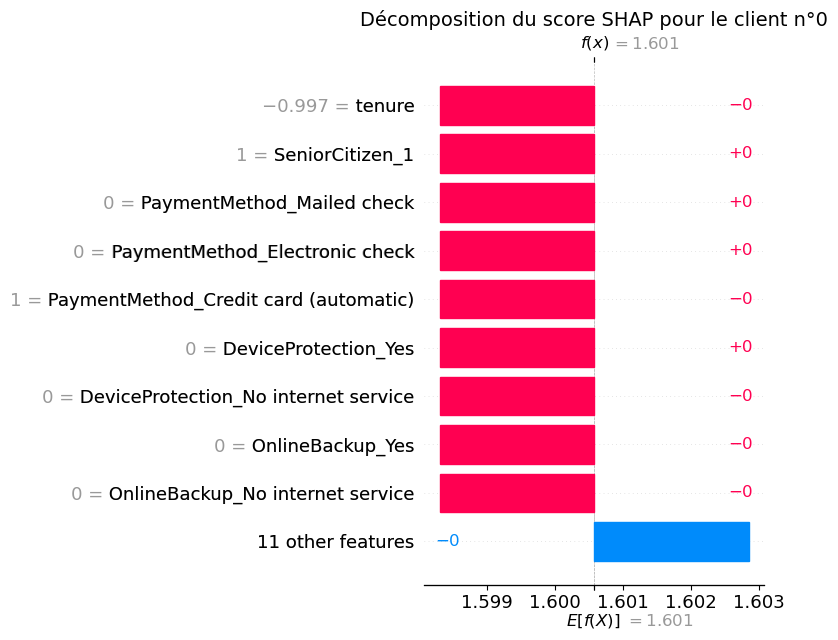

In [45]:
# On cherche un client à haut risque
y_proba_test = final_pipeline.predict_proba(X_test)[:, 1]
high_risk_index = (y_proba_test >= 0.40).argmax()
client_to_explain = X_test.iloc[[high_risk_index]]

# Calcul
shap_values_local, _ = compute_shap_values(final_pipeline, client_to_explain)

# Affichage
plot_shap_waterfall(shap_values_local, client_index=0)

# Interprétation Individuelle (Waterfall Plot - Client n°0)
Ce graphique explique pourquoi le modèle a donné un score spécifique à ce client en particulier.
Sur l'axe des x, les valeurs affichées sont positives, autour de 1.601, il s'agit d'une échelle logarithmique de probabilité (log-odds).

- Le Score Final noté  f(x) = 1.601 : une valeur de 1.603 correspond a une probabilté de Churn d'environ 83 % car (1/ 1 e^-1.601).

- Le Point de Départ : La valeur de base E[f(X)] (la moyenne du modèle) se situe tout à droite de l'axe (à 1.603).
L'écart est extrêmement faible entre 1.599 à 1.603: cela signifie que pour ce client, les caractéristiques individuelles n'ont presque pas modifié le score global. Le modèle prédit un risque élevé principalement parce que "la moyenne de base" du modèle est haute, et non à cause d'un facteur dramatique propre à ce client.

- Les valeurs des variables à gauche indiquent le profil de ce client :
    - tenure = -0.997 : Après standardisation, cela signifie que l'ancienneté réelle de ce client est très proche de 0 mois.
    - SeniorCitizen_1 = 1 : C'est une personne âgée.
    - PaymentMethod_Credit card (automatic) = 1 : Il paie par carte de crédit automatique.
    - DeviceProtection_Yes = 0 et OnlineBackup_Yes = 0 : Il n'a ni protection d'appareil, ni sauvegarde en ligne.
Ainsi, bien que ce client présente un profil à risque (faible ancienneté, senior, peu de services), le graphique montre que l'impact de chacune de ces variables en barres rouges est marginal car les valeurs SHAP sont proches de 0. Les barres rouges tirent très légèrement le score vers la gauche donc vers moins de risque, mais pas assez pour compenser la probabilité de base élevée du modèle.

# HYPERPARAMETRES 

Lancement du GridSearch...
Fitting 5 folds for each of 5 candidates, totalling 25 fits
Meilleur paramètre C trouvé : 0.01
Meilleur F1-Score (Validation Croisée sur le Train) : 0.625


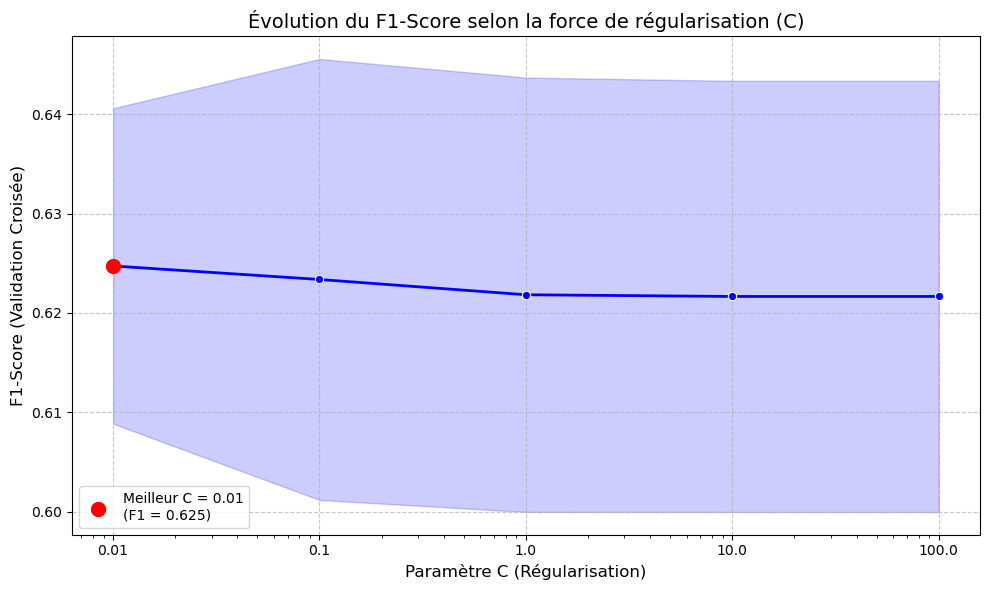

In [57]:
# GridSearch 
print("Lancement du GridSearch...")
grid_search_lr = tune_logistic_regression(X_train, y_train, preprocessor)

# 2graphe
plot_gridsearch_results(grid_search_lr)

# 3. le meilleur modèle pour la suite
best_lr_pipeline = grid_search_lr.best_estimator_

.

# ENTRAINEMENT DES DONNEES SUR LE df_test

In [59]:
from sklearn.metrics import confusion_matrix, recall_score, precision_score, f1_score, roc_auc_score
import numpy as np
import json

# 1. On fait les prédictions sur les données de test (non vues à l'entraînement)
y_proba_test = final_pipeline.predict_proba(X_test)[:, 1]

# 2. On applique notre seuil métier (0.40)
y_pred_metier = (y_proba_test >= 0.40).astype(int)

# 3. Calcul des métriques finales
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_metier).ravel()

metrics = {
    'threshold_used': 0.40,
    'TP': int(tp),
    'TN': int(tn),
    'FP': int(fp),
    'FN': int(fn),
    'Recall': round(recall_score(y_test, y_pred_metier), 3),
    'Precision': round(precision_score(y_test, y_pred_metier), 3),
    'F1_Score': round(f1_score(y_test, y_pred_metier), 3),
    'ROC_AUC': round(roc_auc_score(y_test, y_proba_test), 3)
}

print("--- Performance finale du modèle (Seuil = 0.40) ---")
for key, value in metrics.items():
    print(f"{key} : {value}")

--- Performance finale du modèle (Seuil = 0.40) ---
threshold_used : 0.4
TP : 321
TN : 665
FP : 370
FN : 53
Recall : 0.858
Precision : 0.465
F1_Score : 0.603
ROC_AUC : 0.837


In [60]:
from src.modeling import evaluate_final_model

# 1. Appel de la fonction du module
final_metrics = evaluate_final_model(best_lr_pipeline, X_test, y_test, threshold=0.40)

# 2. Affichage propre (le rôle du notebook)
print("--- Performance finale du modèle (Seuil = 0.40) ---")
for key, value in final_metrics.items():
    print(f"{key} : {value}")

--- Performance finale du modèle (Seuil = 0.40) ---
threshold_used : 0.4
TP : 322
TN : 654
FP : 381
FN : 52
Recall : 0.861
Precision : 0.458
F1_Score : 0.598
ROC_AUC : 0.837


# l- Observation:

Modèle	                      Seuil	TP	  TN	FP	  FN	Recall	Precision	F1-Score	ROC-AUC
---------------------------------------------------------------------------------------------------------------
SVM (Bench)	                  0.50	288	  771	264	  86	0.770	0.522	    0.622	    0.811
---------------------------------------------------------------------------------------------------------------
Logistic Reg (Bench)          0.50	300	  737	298	  74	0.802	0.502	    0.617	    0.837
---------------------------------------------------------------------------------------------------------------
Logistic Reg (Final Optimisé) 0.40	322  654	381	  52	0.861	0.458	    0.598	    0.837
---------------------------------------------------------------------------------------------------------------

# Conclusion statistique
- L'effet du seuil (Threshold) : Le passage du seuil de 0.50 (benchmark) à 0.40 (final) a modifié la matrice de confusion de la Régression Logistique. Les Faux Négatifs (FN) ont chuté de 74 à 52 (soit 22 clients sauvés), tandis que les Faux Positifs (FP) ont augmenté de 298 à 381 (soit 83 alertes supplémentaires).

- En comparaison LR vs SVM : Au seuil de 0.50, le SVM avait un meilleur F1-Score (0.622 vs 0.617). Mais la LR optimisée avec le seuil métier de 0.40 offre un Recall très supérieur (0.861), ce qui correspond à notre objectif prioritaire. Le F1-Score baisse (0.598) car on sacrifie volontairement la précision.

# Conclusion métier sur le choix du modèle
- La Minimisation des pertes (Le gain) : En choisissant la LR optimisée au seuil de 0.40, on ne rate plus que 52 clients (FN) au lieu de 86 avec le SVM. L'entreprise sauve donc 34 clients supplémentaires par rapport au SVM.

- Arbitrage ue coût opérationnel : En contrepartie, les conseillers devront traiter 381 alertes (FP) au lieu de 264 (SVM) ou 298 (LR Benchmark). C'est un arbitrage assumé : "Mieux vaut faire 117 appels de vérification en plus que de perdre 34 clients supplémentaires."

- Le ROC-AUC (La robustesse) : La LR a un ROC-AUC de 0.837 (contre 0.811 pour le SVM). Cela prouve que, indépendamment du seuil choisi, la LR est intrinsèquement plus capable de séparer les futurs churners des clients fidèles sur ce jeu de données.

# Implication pour la modélisation
- La LR optimisée atteint un Recall de 0.861, surpassant largement le SVM (0.770). Dans la rétention client, rater un churner coûte plus cher qu'un faux positif.

- par surenchissement, le SVM est une "boîte noire". La LR fournit des coefficients directs, indispensables pour que le conseiller comprenne le score.

- Le F1-Score plus faible de la LR finale (0.598) est un choix délibéré, pas une faiblesse. Il traduit le fait de privilégier le sauvetage de clients (Recall) sur la pureté des alertes (Précision).

.

# SAUVEGARDE DU MODELE

In [65]:
import os
import joblib
import json

# 1. On définit le chemin ABSOLU en dur (avec les doubles antislashs pour Windows)
model_dir = r"V:\1_PROJETS_DATA_SCIENCE\09_Churn\model"

print(f"Dossier de sauvegarde ciblé : {model_dir}")

# On vérifie que le dossier existe bien (il a été créé par toi)
if not os.path.exists(model_dir):
    print("❌ ERREUR : Le dossier n'existe pas à ce chemin.")
else:
    # 2. Sauvegarder le Pipeline
    pipeline_path = os.path.join(model_dir, "logistic_regression_model.pkl")
    joblib.dump(best_lr_pipeline, pipeline_path)
    print(f"Pipeline sauvegardé : {pipeline_path}")

    # 3. Sauvegarder les métriques
    metrics_path = os.path.join(model_dir, "metrics.json")
    with open(metrics_path, "w") as f:
        json.dump(final_metrics, f, indent=4)
    print(f"Métriques sauvegardées : {metrics_path}")

    # 4. Sauvegarder la configuration métier
    config_path = os.path.join(model_dir, "business_config.json")
    with open(config_path, "w") as f:
        json.dump({"business_threshold": 0.40}, f, indent=4)
    print(f"Configuration sauvegardée : {config_path}")

Dossier de sauvegarde ciblé : V:\1_PROJETS_DATA_SCIENCE\09_Churn\model
Pipeline sauvegardé : V:\1_PROJETS_DATA_SCIENCE\09_Churn\model\logistic_regression_model.pkl
Métriques sauvegardées : V:\1_PROJETS_DATA_SCIENCE\09_Churn\model\metrics.json
Configuration sauvegardée : V:\1_PROJETS_DATA_SCIENCE\09_Churn\model\business_config.json
